# UCS420 Cognitive Computing
## Lab Assignment 9 - Vision based Cognitive System

In [1]:
# N Soma Sekhar
# Roll No: 1024170194

import os
import re
import urllib.request
from datetime import date
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

## Part 1 - Cognitive Assistant for Reading Medicine Labels

Steps:
1. Take an image of the medicine label
2. Preprocess it (grayscale, contrast, denoise)
3. Read the text with OCR (RapidOCR)
4. Extract the name, strength, dosage, batch and expiry using regex
5. Check expiry and give advice using a small knowledge base

To check accuracy I need labels where I already know the correct text, so I made some label images with PIL. I also made blurred and dark versions of them, so they look more like photos taken with a phone camera.

15 images


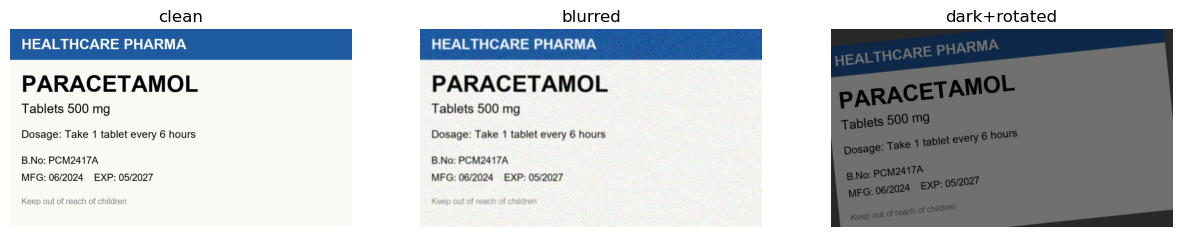

In [2]:
meds = [
    ["PARACETAMOL", "500 mg", "Tablets", "Take 1 tablet every 6 hours", "PCM2417A", "06/2024", "05/2027"],
    ["AMOXICILLIN", "250 mg", "Capsules", "Take 1 capsule three times daily", "AMX5521", "01/2024", "12/2025"],
    ["METFORMIN", "500 mg", "Tablets", "Take 1 tablet twice daily with meals", "MTF0932", "03/2025", "02/2028"],
    ["CETIRIZINE", "10 mg", "Tablets", "Take 1 tablet once daily at bedtime", "CTZ7710", "09/2024", "08/2026"],
    ["IBUPROFEN", "400 mg", "Tablets", "Take 1 tablet every 8 hours after food", "IBU3384", "11/2024", "10/2027"],
]

def get_font(size, bold=False):
    if bold:
        paths = ["C:/Windows/Fonts/arialbd.ttf", "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"]
    else:
        paths = ["C:/Windows/Fonts/arial.ttf", "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"]
    for p in paths:
        if os.path.exists(p):
            return ImageFont.truetype(p, size)
    return ImageFont.load_default()

def make_label(m):
    img = Image.new("RGB", (900, 520), (250, 250, 245))
    d = ImageDraw.Draw(img)
    d.rectangle([0, 0, 900, 80], fill=(30, 90, 160))
    d.text((30, 18), "HEALTHCARE PHARMA", font=get_font(38, True), fill="white")
    d.text((30, 110), m[0], font=get_font(60, True), fill="black")
    d.text((30, 190), m[2] + " " + m[1], font=get_font(34), fill="black")
    d.text((30, 260), "Dosage: " + m[3], font=get_font(28), fill="black")
    d.text((30, 330), "B.No: " + m[4], font=get_font(26), fill="black")
    d.text((30, 375), "MFG: " + m[5] + "    EXP: " + m[6], font=get_font(26), fill="black")
    d.text((30, 440), "Keep out of reach of children", font=get_font(22), fill="gray")
    return cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)

def blur_it(img):
    img = cv2.GaussianBlur(img, (5, 5), 1.6)
    noise = np.random.normal(0, 20, img.shape)
    return np.clip(img + noise, 0, 255).astype(np.uint8)

def dark_it(img):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w/2, h/2), 6, 1)
    img = cv2.warpAffine(img, M, (w, h), borderValue=(90, 90, 90))
    return (img * 0.45).astype(np.uint8)

np.random.seed(0)
images = []
for m in meds:
    clean = make_label(m)
    images.append([m, "clean", clean])
    images.append([m, "blurred", blur_it(clean)])
    images.append([m, "dark+rotated", dark_it(clean)])

print(len(images), "images")

plt.figure(figsize=(15, 4))
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(cv2.cvtColor(images[i][2], cv2.COLOR_BGR2RGB))
    plt.title(images[i][1])
    plt.axis("off")
plt.show()

### Preprocessing

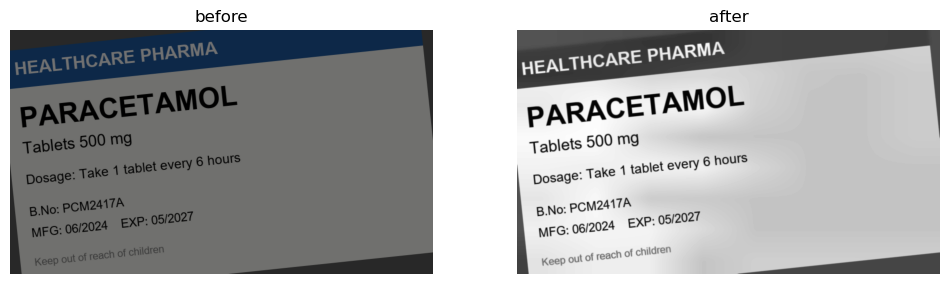

In [3]:
def preprocess(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, None, fx=1.5, fy=1.5)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    gray = clahe.apply(gray)
    gray = cv2.fastNlMeansDenoising(gray, h=12)
    return gray

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(images[2][2], cv2.COLOR_BGR2RGB))
plt.title("before")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(preprocess(images[2][2]), cmap="gray")
plt.title("after")
plt.axis("off")
plt.show()

### OCR

In [4]:
from rapidocr_onnxruntime import RapidOCR
ocr = RapidOCR()

def read_text(img):
    result, t = ocr(preprocess(img))
    lines = []
    if result:
        for r in result:
            lines.append(r[1])
    return lines

lines = read_text(images[1][2])
for l in lines:
    print(l)

HEALTHCAREPHARMA
PARACETAMOL
Tablets500 mg
Dosage:Take 1 tablet every 6 hours
B.No:PCM2417A
MFG:06/2024EXP:05/2027
Kaep out of rench ot childron


OCR sometimes joins words together (like Take1tabletevery6hours) or reads O as 0, so for the regex I remove all the spaces and keep the patterns loose.

### Extracting information

In [5]:
import difflib

drug_info = {
    "PARACETAMOL": ["fever and pain", "max 4000 mg per day for adults", "avoid alcohol, can damage liver in overdose"],
    "AMOXICILLIN": ["bacterial infections (antibiotic)", "as prescribed by doctor", "do not take if allergic to penicillin, finish the full course"],
    "METFORMIN": ["type 2 diabetes", "as prescribed by doctor", "take with meals to avoid stomach upset"],
    "CETIRIZINE": ["allergy", "10 mg per day for adults", "can cause sleepiness, avoid driving"],
    "IBUPROFEN": ["pain, fever and swelling", "max 1200 mg per day without prescription", "take after food, avoid if you have stomach ulcers"],
}

def extract(lines):
    text = ""
    for l in lines:
        text = text + " " + l.lower().replace(" ", "")

    info = {}

    info["name"] = None
    for l in lines:
        for w in l.split():
            match = difflib.get_close_matches(w.upper(), drug_info.keys(), n=1, cutoff=0.75)
            if match:
                info["name"] = match[0]

    m = re.search(r"(\d+)mg", text)
    info["strength"] = m.group(1) + " mg" if m else None

    m = re.search(r"exp\W*(\d{2}/\d{4})", text)
    info["expiry"] = m.group(1) if m else None

    m = re.search(r"b\.?n[o0]\W*([a-z0-9]+)", text)
    info["batch"] = m.group(1).upper() if m else None

    times = None
    m = re.search(r"every(\d+)hours", text)
    if m:
        times = 24 // int(m.group(1))
    elif "threetimes" in text:
        times = 3
    elif "twice" in text:
        times = 2
    elif "once" in text:
        times = 1
    info["times_per_day"] = times
    return info

print(extract(lines))

{'name': 'PARACETAMOL', 'strength': '500 mg', 'expiry': '05/2027', 'batch': 'PCM2417A', 'times_per_day': 4}


### Reasoning and response

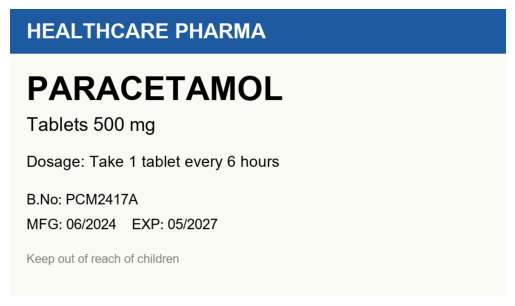

This is PARACETAMOL 500 mg, used for fever and pain.
It is valid till 05/2027.
Take it 4 times a day.
Max dose: max 4000 mg per day for adults.
Note: avoid alcohol, can damage liver in overdose.
Please confirm with your doctor or pharmacist.



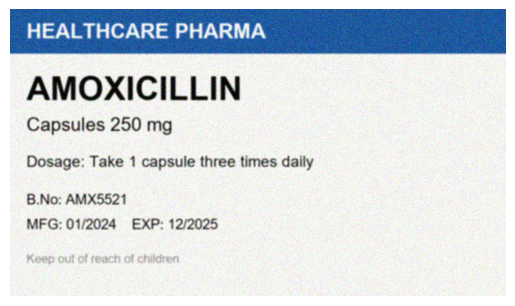

This is AMOXICILLIN 250 mg, used for bacterial infections (antibiotic).
Take it 3 times a day.
Max dose: as prescribed by doctor.
Note: do not take if allergic to penicillin, finish the full course.
Please confirm with your doctor or pharmacist.



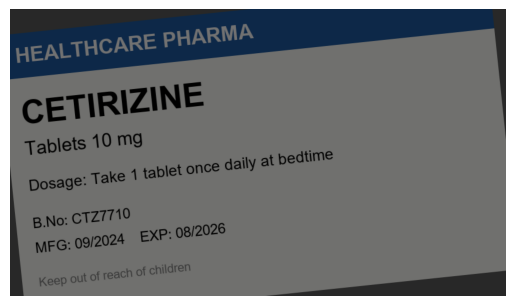

This is CETIRIZINE 10 mg, used for allergy.
Take it 1 times a day.
Max dose: 10 mg per day for adults.
Note: can cause sleepiness, avoid driving.
Please confirm with your doctor or pharmacist.



In [6]:
today = date.today()

def check_expiry(exp):
    month = int(exp.split("/")[0])
    year = int(exp.split("/")[1])
    if year < today.year or (year == today.year and month < today.month):
        return True
    return False

def label_assistant(img):
    info = extract(read_text(img))
    if info["name"] == None or info["expiry"] == None:
        return "Sorry, I could not read the label clearly. Please take the photo again in better light."

    d = drug_info[info["name"]]
    msg = "This is " + info["name"] + " " + str(info["strength"]) + ", used for " + d[0] + ".\n"
    if check_expiry(info["expiry"]):
        msg = msg + "WARNING: This medicine EXPIRED in " + info["expiry"] + ". Do not take it.\n"
    else:
        msg = msg + "It is valid till " + info["expiry"] + ".\n"
    if info["times_per_day"] != None:
        msg = msg + "Take it " + str(info["times_per_day"]) + " times a day.\n"
    msg = msg + "Max dose: " + d[1] + ".\n"
    msg = msg + "Note: " + d[2] + ".\n"
    msg = msg + "Please confirm with your doctor or pharmacist."
    return msg

for i in [0, 4, 11]:
    plt.imshow(cv2.cvtColor(images[i][2], cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()
    print(label_assistant(images[i][2]))
    print()

### Accuracy

In [7]:
correct_times = {"PARACETAMOL": 4, "AMOXICILLIN": 3, "METFORMIN": 2, "CETIRIZINE": 1, "IBUPROFEN": 3}
rows = []
for m, cond, img in images:
    info = extract(read_text(img))
    rows.append({
        "drug": m[0],
        "condition": cond,
        "name": info["name"] == m[0],
        "strength": info["strength"] == m[1],
        "expiry": info["expiry"] == m[6],
        "batch": info["batch"] == m[4],
        "frequency": info["times_per_day"] == correct_times[m[0]],
    })

res = pd.DataFrame(rows)
res

,drug,condition,name,strength,expiry,batch,frequency
0,PARACETAMOL,clean,True,True,True,True,True
1,PARACETAMOL,blurred,True,True,True,True,True
2,PARACETAMOL,dark+rotated,True,True,True,True,True
3,AMOXICILLIN,clean,True,True,True,True,True
4,AMOXICILLIN,blurred,True,True,True,True,True
5,AMOXICILLIN,dark+rotated,True,True,True,True,True
6,METFORMIN,clean,True,True,True,True,True
7,METFORMIN,blurred,True,True,True,True,True
8,METFORMIN,dark+rotated,True,True,True,True,True
9,CETIRIZINE,clean,True,True,True,True,True


In [8]:
print(res.groupby("condition")[["name", "strength", "expiry", "batch", "frequency"]].mean() * 100)

               name  strength  expiry  batch  frequency
condition                                              
blurred       100.0     100.0   100.0  100.0      100.0
clean         100.0     100.0   100.0  100.0      100.0
dark+rotated  100.0     100.0   100.0  100.0      100.0


All the fields were read correctly for the clean, blurred and dark labels. Real medicine bottles are curved and shiny, so the accuracy on them will be lower.

### Testing on a real photo

In [9]:
os.makedirs("lab9_data/real_labels", exist_ok=True)
files = os.listdir("lab9_data/real_labels")
if len(files) == 0:
    print("no real photos in lab9_data/real_labels")
for f in files:
    img = cv2.imread("lab9_data/real_labels/" + f)
    print(f)
    print(label_assistant(img))

no real photos in lab9_data/real_labels


## Part 2 - Emotion aware Cognitive Assistant

Steps:
1. Detect the face using the OpenCV Haar cascade
2. Find the emotion using the FER+ model (a CNN from the ONNX model zoo, trained on FER-2013 faces with 8 emotions)
3. Give a reply based on the emotion
4. Remember the last few emotions, and if the user is upset for a long time, check on them

In [10]:
import onnxruntime as ort

os.makedirs("lab9_data", exist_ok=True)
model_path = "lab9_data/emotion-ferplus-8.onnx"
if not os.path.exists(model_path):
    url = "https://github.com/onnx/models/raw/main/validated/vision/body_analysis/emotion_ferplus/model/emotion-ferplus-8.onnx"
    urllib.request.urlretrieve(url, model_path)

sess = ort.InferenceSession(model_path)
emotions = ["neutral", "happiness", "surprise", "sadness", "anger", "disgust", "fear", "contempt"]
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

In [11]:
def get_emotion(face):
    face = cv2.resize(face, (64, 64)).astype(np.float32)
    face = face.reshape(1, 1, 64, 64)
    out = sess.run(None, {sess.get_inputs()[0].name: face})[0][0]
    prob = np.exp(out) / np.sum(np.exp(out))
    return emotions[np.argmax(prob)], np.max(prob)

def detect(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, 1.1, 5)
    results = []
    for (x, y, w, h) in faces:
        emo, p = get_emotion(gray[y:y+h, x:x+w])
        results.append([emo, p])
        cv2.rectangle(img, (x, y), (x+w, y+h), (0, 255, 0), 2)
        cv2.putText(img, emo + " " + str(round(p, 2)), (x, y-10), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    return img, results

### Test image 1 - astronaut photo (from skimage)

[['happiness', 0.9999889]]


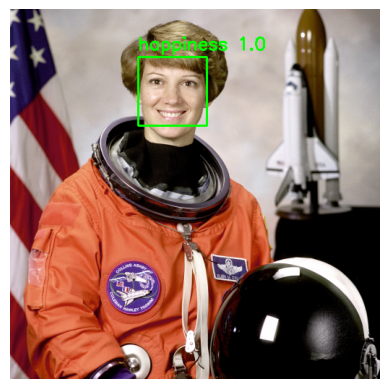

In [12]:
from skimage import data

img = cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR)
img, res = detect(img)
print(res)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

### Test image 2 - Olivetti faces dataset (downloaded with sklearn)

neutral      246
happiness    153
surprise       1
Name: count, dtype: int64


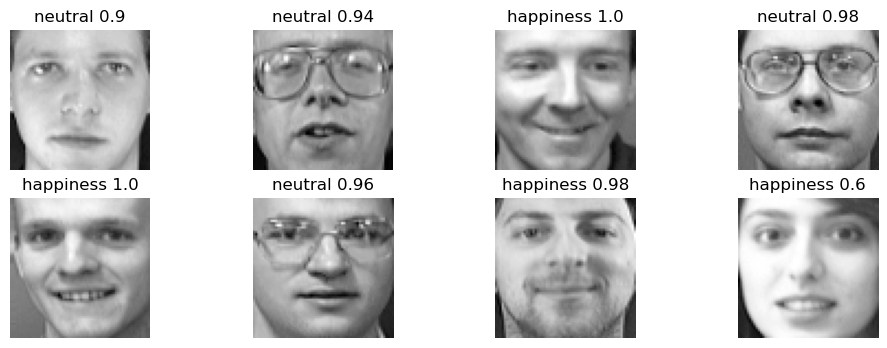

In [13]:
from sklearn.datasets import fetch_olivetti_faces

faces = fetch_olivetti_faces(data_home="lab9_data/sklearn")
imgs = (faces.images * 255).astype(np.uint8)

preds = []
for f in imgs:
    e, p = get_emotion(f)
    preds.append(e)
print(pd.Series(preds).value_counts())

plt.figure(figsize=(12, 4))
for i in range(8):
    e, p = get_emotion(imgs[i * 10])
    plt.subplot(2, 4, i+1)
    plt.imshow(imgs[i * 10], cmap="gray")
    plt.title(e + " " + str(round(p, 2)))
    plt.axis("off")
plt.show()

These photos are mostly calm faces with a few smiles, so the model predicts mostly neutral and happiness. That makes sense for this dataset.

### The assistant

In [14]:
replies = {
    "happiness": "You look happy! Lets continue.",
    "neutral": "I am here if you need any help.",
    "surprise": "You look surprised, do you want me to explain again?",
    "sadness": "You seem a bit sad. Do you want to take a short break?",
    "anger": "You look frustrated. Lets slow down and try again step by step.",
    "fear": "Dont worry, we can go slowly.",
    "disgust": "Do you want to try something else?",
    "contempt": "Tell me if something is not working for you.",
}
negative = ["sadness", "anger", "fear", "disgust", "contempt"]

history = []

def emotion_assistant(emo, p):
    history.append(emo)
    if p < 0.4:
        return "Not sure about your emotion."
    last = history[-4:]
    neg_count = 0
    for e in last:
        if e in negative:
            neg_count = neg_count + 1
    if neg_count == 4:
        return "You have looked upset for a while. Maybe take a break or talk to someone you trust."
    return replies[emo]

print(emotion_assistant(res[0][0], res[0][1]))

You look happy! Lets continue.


To test the memory part, I made a fake session where I give the emotions one by one, like frames from a webcam.

In [15]:
history = []
session = [("happiness", 0.9), ("happiness", 0.8), ("neutral", 0.7), ("sadness", 0.3),
           ("sadness", 0.8), ("sadness", 0.85), ("anger", 0.7), ("sadness", 0.9)]
for e, p in session:
    print(e, p, "->", emotion_assistant(e, p))

happiness 0.9 -> You look happy! Lets continue.
happiness 0.8 -> You look happy! Lets continue.
neutral 0.7 -> I am here if you need any help.
sadness 0.3 -> Not sure about your emotion.
sadness 0.8 -> You seem a bit sad. Do you want to take a short break?
sadness 0.85 -> You seem a bit sad. Do you want to take a short break?
anger 0.7 -> You have looked upset for a while. Maybe take a break or talk to someone you trust.
sadness 0.9 -> You have looked upset for a while. Maybe take a break or talk to someone you trust.


When the emotion is not clear (p < 0.4), the assistant does not react. After 4 negative emotions in a row, it asks the user to take a break.

### Webcam (run in Google Colab)

In [16]:
try:
    from google.colab.output import eval_js
    from IPython.display import display, Javascript
    from base64 import b64decode
    colab = True
except:
    colab = False

def take_photo(filename="photo.jpg"):
    js = Javascript("""
    async function takePhoto() {
      const div = document.createElement('div');
      const btn = document.createElement('button');
      btn.textContent = 'Capture';
      div.appendChild(btn);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => btn.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', 0.8);
    }""")
    display(js)
    data = eval_js("takePhoto()")
    f = open(filename, "wb")
    f.write(b64decode(data.split(",")[1]))
    f.close()
    return filename

if colab:
    img = cv2.imread(take_photo())
    img, res = detect(img)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.show()
    for e, p in res:
        print(emotion_assistant(e, p))
else:
    print("not running in colab, skipping webcam")

not running in colab, skipping webcam


## Conclusion
- The medicine label assistant reads the label with OCR, finds the important details with regex, checks whether the medicine has expired and gives simple advice. If it cannot read the label, it asks for a new photo instead of guessing.
- The emotion assistant detects the face, predicts the emotion with a CNN, and changes its reply based on the emotion and on the recent history.
- Limitations: real bottles are harder to read than my generated labels. Emotion models can be wrong, and a face expression does not always show how a person really feels. Face images are private data, so the user's permission is needed.